# Robustness of Chimera States in Coupled FitzHugh-Nagumo Oscillators

This notebook follows the order of the paper. First I set up the FHN model, then I test what happens when I change the oscillators or the connection pattern. A flat part in the phase-velocity plot means coherent motion, while an arc means incoherent motion.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

In [ ]:
# the fractal connection matrix is used in the last section
def build_fractal_matrix(base_pattern, iterations=4):
    #cantor type construction. The kernel is one-sided: node k links to k + offset
    # wherever the kernel has a 1. The self link (offset 0) is removed.
    s = [1]
    for _ in range(iterations):
        nxt = []
        for sym in s:
            nxt.extend(base_pattern if sym == 1 else [0] * len(base_pattern))
        s = nxt

    kernel = np.asarray(s, dtype=float)
    kernel[0] = 0.0  # remove self coupling
    N = len(kernel)
    C = np.zeros((N, N), dtype=float)
    for k in range(N):
        C[k] = np.roll(kernel, k)
    return C

## II. Model and shared setup

This cell has the FHN model and the helper functions used in every simulation below. I made N smaller so it runs without taking forever. N_run = 1000 & T_run = 2500 are the paper values.

In [ ]:
N_run = 1000
T_run = 2500
RTOL, ATOL = 1e-4, 1e-6
epsilon = 0.05
a_mean = 0.5
phi = np.pi / 2 - 0.1
buu, buv = np.cos(phi), np.sin(phi)
bvu, bvv = -np.sin(phi), np.cos(phi)

def sc(x):
    # gap/link counts in the paper are given for N = 1000, so scale them with N_run
    return int(round(x * N_run / 1000))

In [ ]:
def ring_matrix(N, R):
    C = np.zeros((N, N), dtype=float)
    off = np.r_[np.arange(-R, 0), np.arange(1, R + 1)]
    for k in range(N):
        C[k, (k + off) % N] = 1
    return C

def add_shortcuts(C, p, seed=1):
    #keep the original ring links and randomly add some extra ones
    #keep every ring link and add each missing pair with probability p (symmetric)
    rng = np.random.default_rng(seed)
    N = len(C)
    new = np.triu(C == 0, 1) & (rng.random((N, N)) < p)
    return np.maximum(C, (new | new.T).astype(float))

def rewire_links(C, p, seed=1):
    #instead of adding links, replace some of the old ring links
    # classic small-world rewiring, every existing link is moved with probability p
    rng = np.random.default_rng(seed)
    C_new = C.copy()
    N = len(C_new)
    for i, j in np.argwhere(np.triu(C_new, 1) == 1):
        if rng.random() < p:
            C_new[i, j] = C_new[j, i] = 0
            choices = (C_new[i] == 0)
            choices[i] = False
            choices[j] = False  # do not put the link back where it was
            available = np.flatnonzero(choices)
            if available.size == 0:
                C_new[i, j] = C_new[j, i] = 1
                continue
            new_j = rng.choice(available)
            C_new[i, new_j] = C_new[new_j, i] = 1
    return C_new

def symmetric_gap_matrix(N, R1, R2, G):
    #R1 links are close to the node, then there is a gap, then R2 farther links
    # R1 links next to the node, a gap of G, then R2 links; same on both sides (Eq. 5)
    off = np.r_[np.arange(-R1, R1 + 1),
                np.arange(R1 + G + 1, R1 + G + R2 + 1),
                -np.arange(R1 + G + 1, R1 + G + R2 + 1)]
    off = off[off != 0]
    C = np.zeros((N, N), dtype=float)
    for k in range(N):
        C[k, (k + off) % N] = 1
    return C

def one_sided_gap_matrix(N, R1, R2, G):
    #all links point to the right here, with one gap in between
    # all links to the right, with one gap (Eq. 6 with R3 = R4 = GL = 0)
    off = np.r_[np.arange(1, R1 + 1),
                np.arange(R1 + G + 1, R1 + G + R2 + 1)]
    C = np.zeros((N, N), dtype=float)
    for k in range(N):
        C[k, (k + off) % N] = 1
    return C

In [ ]:
def simulate_fhn(C, sigma, a_values=a_mean, seed=42, T=None, dt_out=0.2,
                 chunk=100.0, rtol=RTOL, atol=ATOL):
    """Integrate the FHN network and return final u_k and mean phase velocity omega_k.

    The first half of the run is discarded as transient. During the second half,
    phase is sampled at intervals no larger than dt_out and wrapped increments
    are accumulated. Chunking limits memory use without changing the measurement
    window or its duration.
    """
    T = T_run if T is None else float(T)
    if T <= 0 or dt_out <= 0 or chunk <= 0:
        raise ValueError("T, dt_out and chunk must be positive.")

    N = C.shape[0]
    degree = C.sum(axis=1)
    if np.any(degree == 0):
        raise ValueError("Every oscillator needs at least one connection.")

    a = (np.full(N, a_values, dtype=float) if np.isscalar(a_values)
         else np.asarray(a_values, dtype=float))
    if a.shape != (N,):
        raise ValueError("a_values must be a scalar or an array of length N.")

    CT = np.ascontiguousarray(C.T)
    coupling_weight = sigma / degree

    def rhs(t, y):
        X = y.reshape(2, N)
        D = X @ CT - X * degree
        coupling_u = buu * D[0] + buv * D[1]
        coupling_v = bvu * D[0] + bvv * D[1]
        du = (X[0] - X[0]**3 / 3 - X[1] + coupling_weight * coupling_u) / epsilon
        dv = X[0] + a + coupling_weight * coupling_v
        return np.r_[du, dv]

    rng = np.random.default_rng(seed)
    theta = rng.uniform(0, 2 * np.pi, N)
    y0 = np.r_[2 * np.cos(theta), 2 * np.sin(theta)]

    # transient (nothing stored)
    transient = solve_ivp(rhs, (0, T / 2), y0, method="DOP853",
                          rtol=rtol, atol=atol)
    if not transient.success:
        raise RuntimeError(transient.message)
    y = transient.y[:, -1]

    # measurement window, processed in chunks so memory stays small
    t_start, t_end = T / 2, T
    n_steps = int(np.ceil((t_end - t_start) / dt_out))
    measurement_times = np.linspace(t_start, t_end, n_steps + 1)
    prev = np.arctan2(y[N:], y[:N])
    total_phase = np.zeros(N)

    start_idx = 0
    while start_idx < n_steps:
        end_idx = min(start_idx + max(1, int(np.floor(chunk / dt_out))), n_steps)
        t_eval = measurement_times[start_idx + 1:end_idx + 1]
        sol = solve_ivp(rhs, (measurement_times[start_idx], measurement_times[end_idx]),
                        y, method="DOP853", t_eval=t_eval, rtol=rtol, atol=atol)
        if not sol.success or sol.y.shape[1] != len(t_eval):
            raise RuntimeError(sol.message if not sol.success else "Incomplete integration output.")

        angles = np.arctan2(sol.y[N:], sol.y[:N])
        increments = np.diff(np.vstack([prev, angles.T]), axis=0)
        wrapped = (increments + np.pi) % (2 * np.pi) - np.pi
        total_phase += wrapped.sum(axis=0)

        prev = angles[:, -1]
        y = sol.y[:, -1]
        start_idx = end_idx

    measurement_duration = t_end - t_start
    omega = total_phase / measurement_duration
    return y[:N], omega


def plot_case(u, omega, title):
    fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
    ax[0].plot(u, "k.", ms=2)
    ax[0].set(xlabel="Node k", ylabel="u_k", title="Snapshot")
    ax[1].plot(omega, "k.", ms=2)
    ax[1].set(xlabel="Node k", ylabel="Mean phase velocity", title=title)
    ax[1].ticklabel_format(useOffset=False)
    for axis in ax:
        axis.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()


def coherent_level(omega, bin_width=0.01):
    """Estimate the coherent plateau from the most populated omega histogram bin."""
    omega = np.asarray(omega, dtype=float)
    if omega.ndim != 1 or omega.size == 0:
        raise ValueError("omega must be a non-empty one-dimensional array.")
    if not np.all(np.isfinite(omega)):
        raise ValueError("omega contains non-finite values.")
    if np.ptp(omega) == 0:
        return float(omega[0])
    edges = np.arange(omega.min(), omega.max() + 2 * bin_width, bin_width)
    counts, edges = np.histogram(omega, bins=edges)
    i = int(np.argmax(counts))
    selected = omega[(omega >= edges[i]) & (omega < edges[i + 1])]
    return float(np.median(selected))


def coherence_measures(omega, c=0.05):
    #Eqs 7 and 8 and the quantities of Figs. 8 and 10
    # N_incoh counts frequencies above the coherent plateau by more than c
    # M_incoh sums absolute deviations from that plateau
    w0 = coherent_level(omega)
    deviation = omega - w0
    return {
        "omega_coh": w0,
        "delta_omega": float(np.max(np.abs(deviation))),
        "N_incoh": float(np.mean(deviation > c)),
        "M_incoh": float(np.sum(np.abs(deviation))),
    }


def looks_like_chimera(omega, tol=0.02, min_peak=0.05):
    # flat plateau (coherent) + a clearly raised part (incoherent).
    deviation = np.abs(omega - coherent_level(omega))
    coherent_fraction = np.mean(deviation < tol)
    return (0.1 < coherent_fraction < 0.9) and deviation.max() > min_peak

## III. Different oscillators

The first section was already doing this. These are the three cases in the paper: one, two, and three incoherent regions.

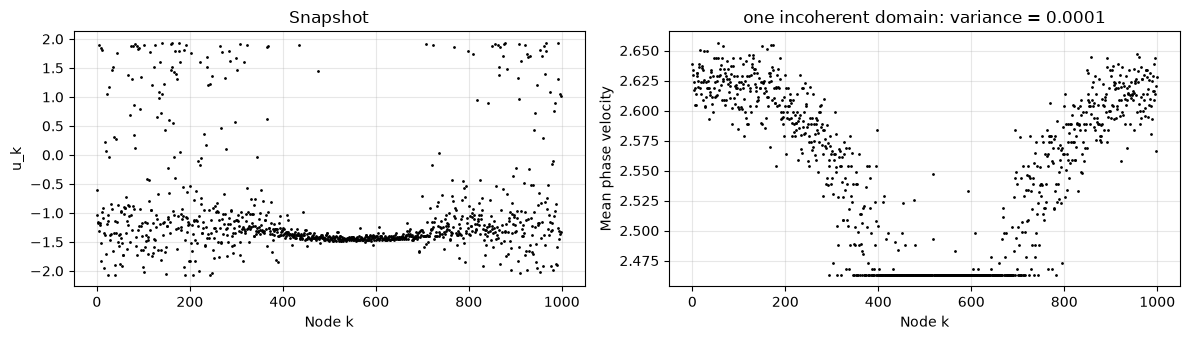

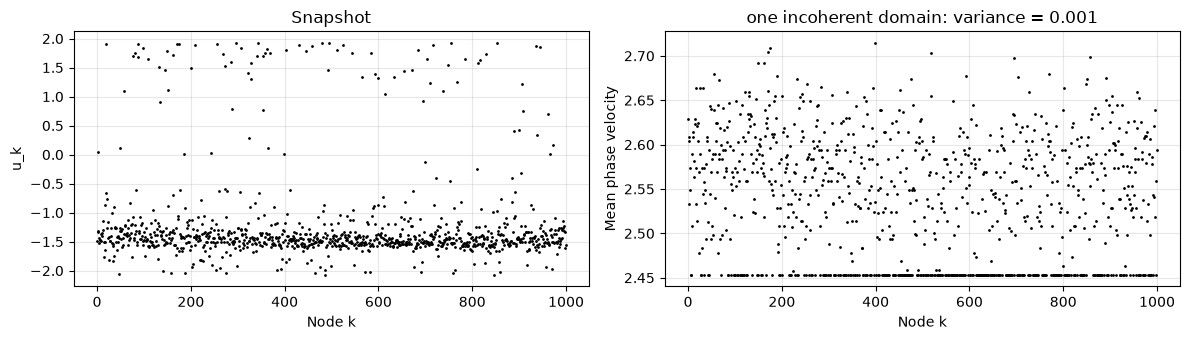

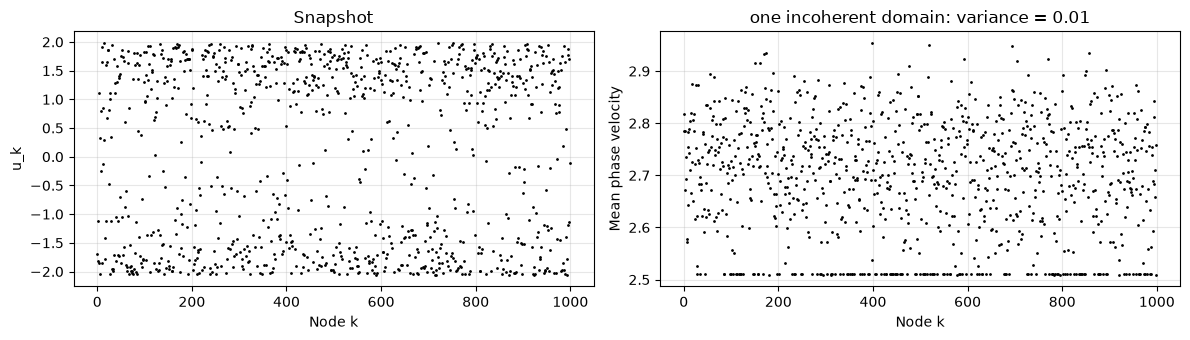

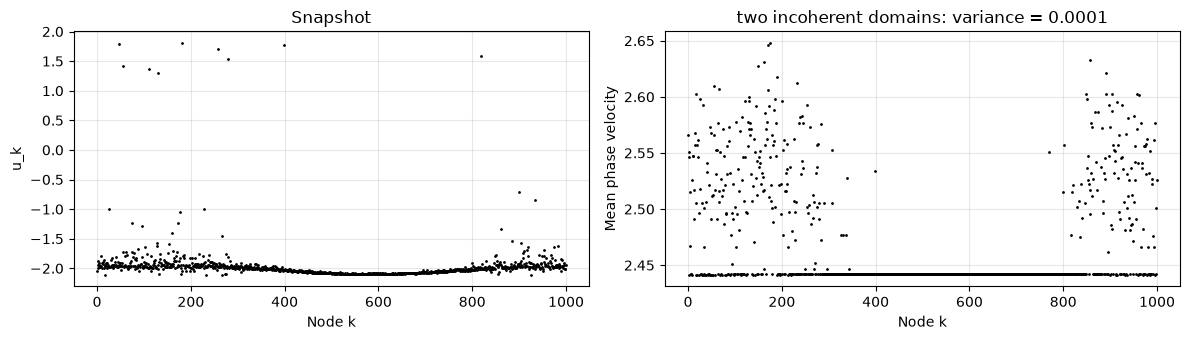

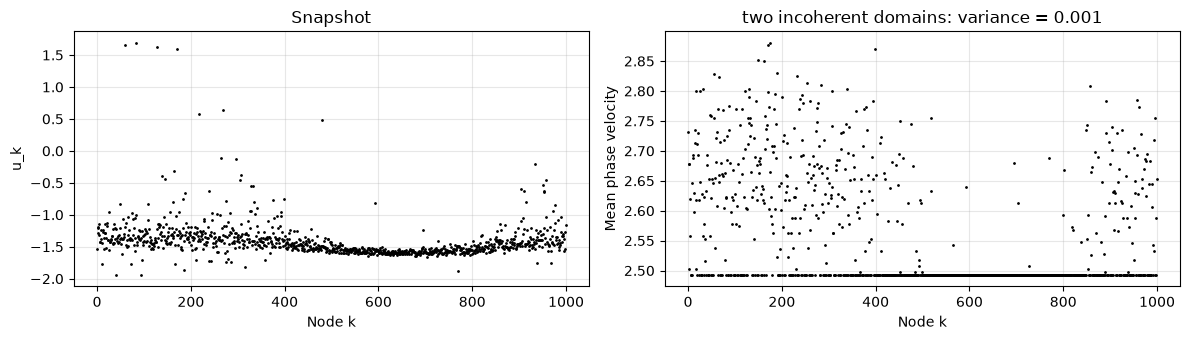

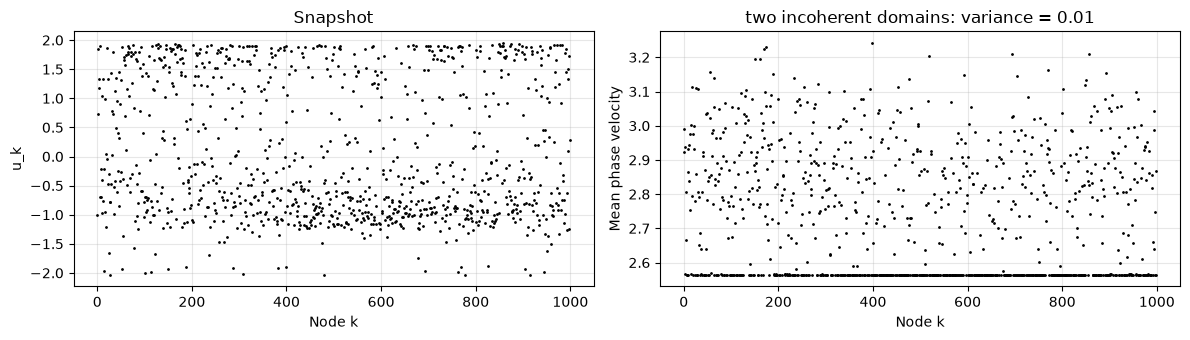

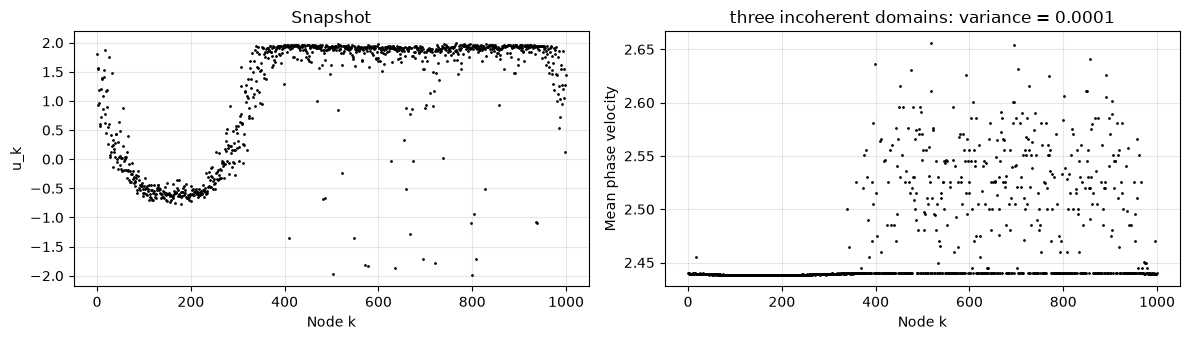

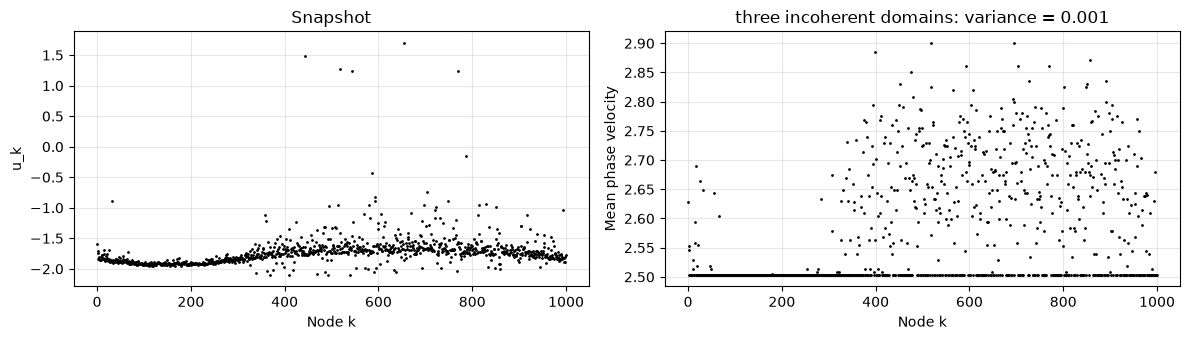

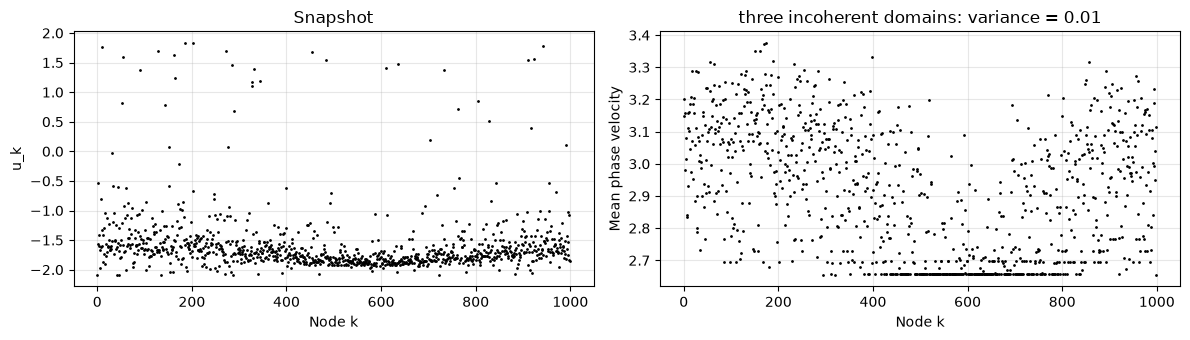

In [6]:
inhomogeneous_cases = [(0.35, 0.10, 'one incoherent domain'),
                       (0.33, 0.28, 'two incoherent domains'),
                       (0.25, 0.25, 'three incoherent domains')]
for r_case, sigma_case, label in inhomogeneous_cases:
    R_case = int(r_case * N_run)
    C = ring_matrix(N_run, R_case)
    for delta_a in [0.0001, 0.001, 0.01]:
        rng = np.random.default_rng(10)
        a_k = rng.normal(a_mean, np.sqrt(delta_a), N_run)
        u, omega = simulate_fhn(C, sigma_case, a_k, seed=42)
        plot_case(u, omega, f'{label}: variance = {delta_a}')

## IV. Random extra links and rewiring

first I keep the normal ring and add random long distance links. Then I try rewiring, where some of the original links are removed and changed.

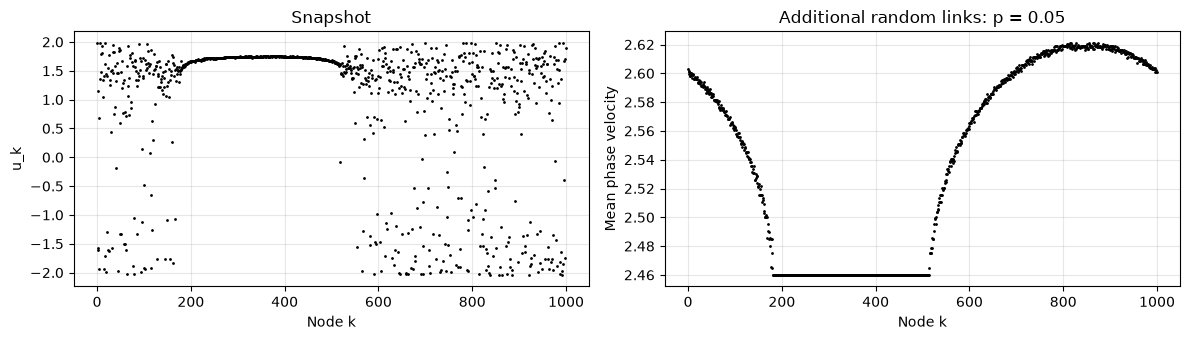

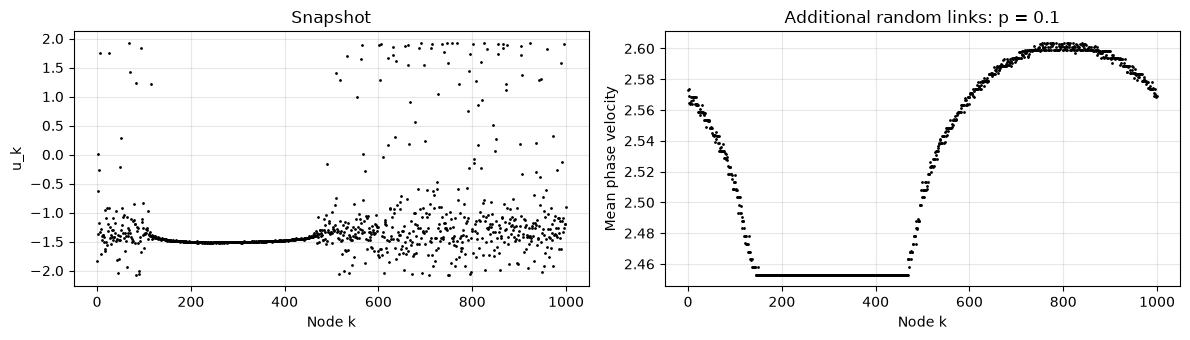

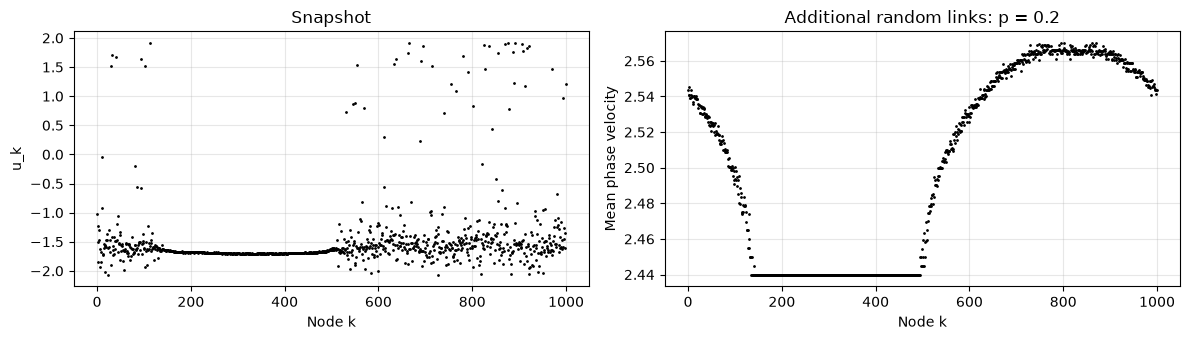

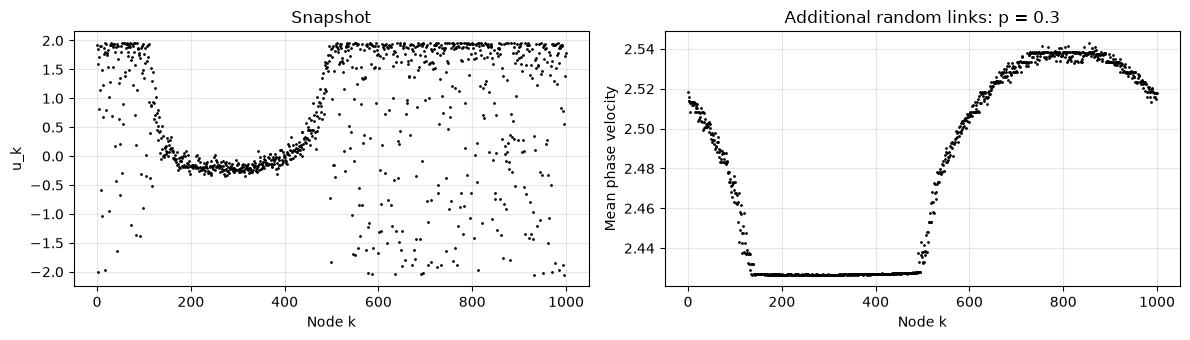

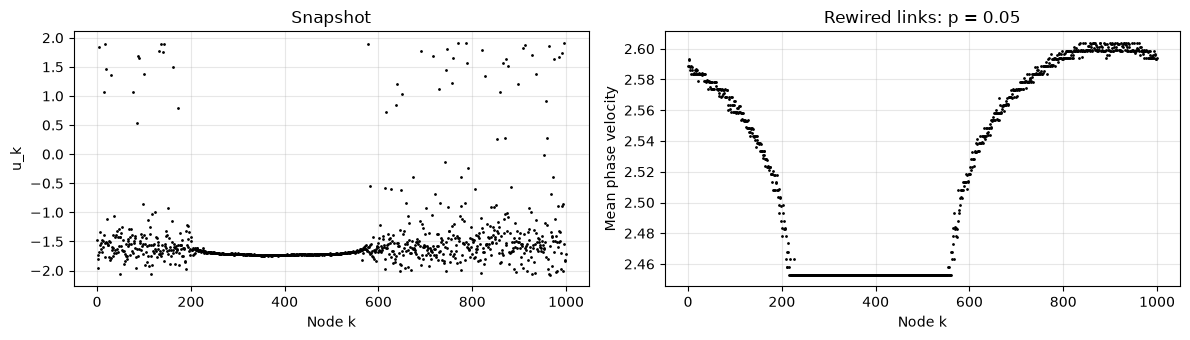

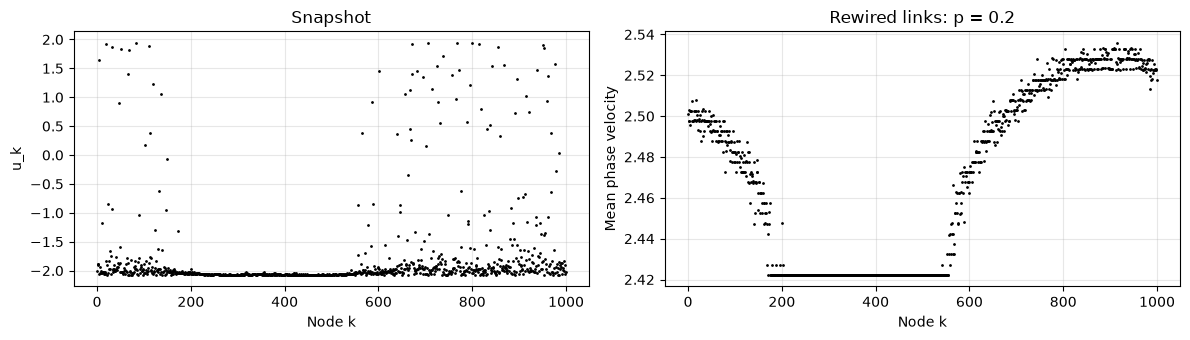

In [ ]:
R_case = int(0.35 * N_run)
C_ring = ring_matrix(N_run, R_case)

for p in [0.05, 0.10, 0.20, 0.30]:
    C_shortcuts = add_shortcuts(C_ring, p, seed=7)
    u, omega = simulate_fhn(C_shortcuts, sigma=0.10, seed=42)
    plot_case(u, omega, f'Additional random links: p = {p}')

for p in [0.05, 0.20]:
    C_rewired = rewire_links(C_ring, p, seed=7)
    u, omega = simulate_fhn(C_rewired, sigma=0.10, seed=42)
    plot_case(u, omega, f'Rewired links: p = {p}')

In [ ]:
#test like Fig. 4. It counts a profile if it has a flat part and an arc part
RUN_STABILITY_SCAN = False    #500 runs is what the paper uses but it takes a long time
if RUN_STABILITY_SCAN:
    N_scan, T_scan, trials = 300, 400, 5
    r_values = [0.25, 0.30, 0.35]
    sigma_values = [0.10, 0.20, 0.30]
    p_values = [0, 0.05, 0.10, 0.20]
    fraction = np.zeros((len(p_values), len(r_values), len(sigma_values)))
    
    for ip, p in enumerate(p_values):
        for ir, r_case in enumerate(r_values):
            C0 = ring_matrix(N_scan, int(round(r_case * N_scan)))

            for js, sigma_case in enumerate(sigma_values):
                hits = 0
                for trial in range(trials):
                    C = add_shortcuts(C0, p, seed=trial)
                    _, omega = simulate_fhn(C, sigma_case, seed=trial, T=T_scan)
                    hits += looks_like_chimera(omega)
                fraction[ip, ir, js] = hits / trials
                
    #one heatmap for each probability so we can see how the stable area moves
    fig, axes = plt.subplots(1, len(p_values), figsize=(14, 3), sharey=True)
    for ax, p, values in zip(axes, p_values, fraction):
        im = ax.imshow(values.T, origin="lower", vmin=0, vmax=1, aspect="auto")
        ax.set(title=f"p = {p}", xlabel="coupling radius index",
               ylabel="coupling strength index")
    fig.colorbar(im, ax=axes, label="fraction of chimera realizations")
    plt.tight_layout()
    plt.show()

## V. Putting gaps in the connections

Here every oscillator still has the same number of links. I only move the gap around to see how the position changes the chimera.

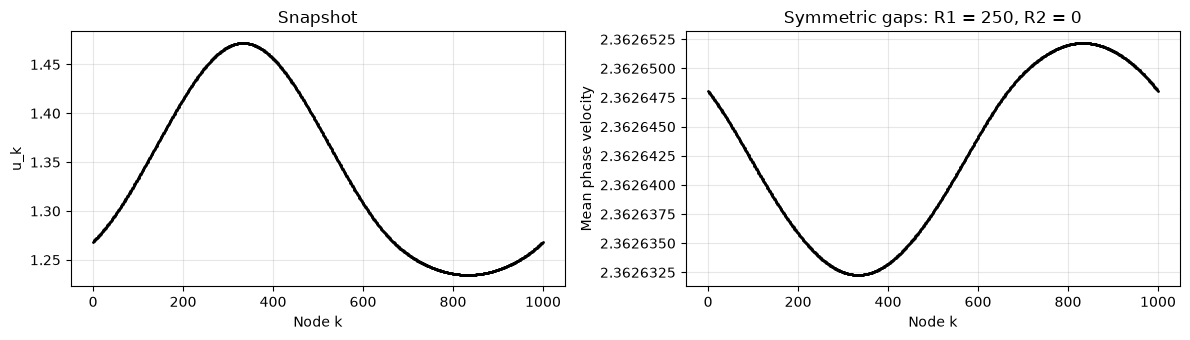

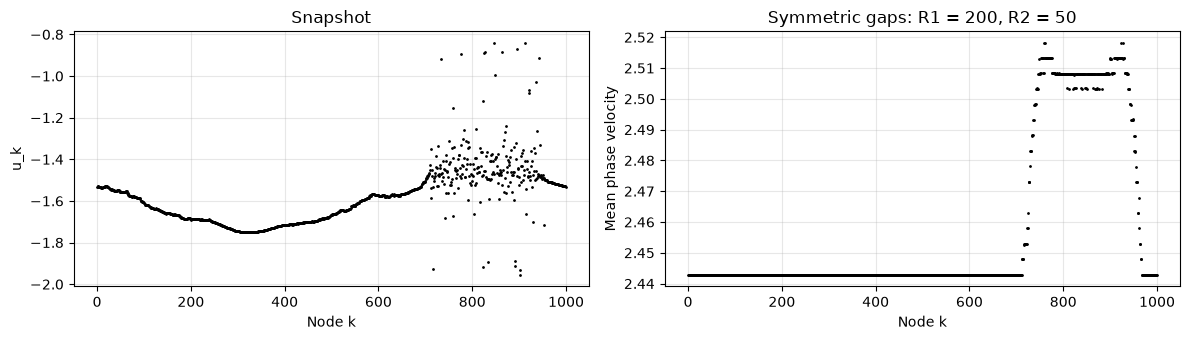

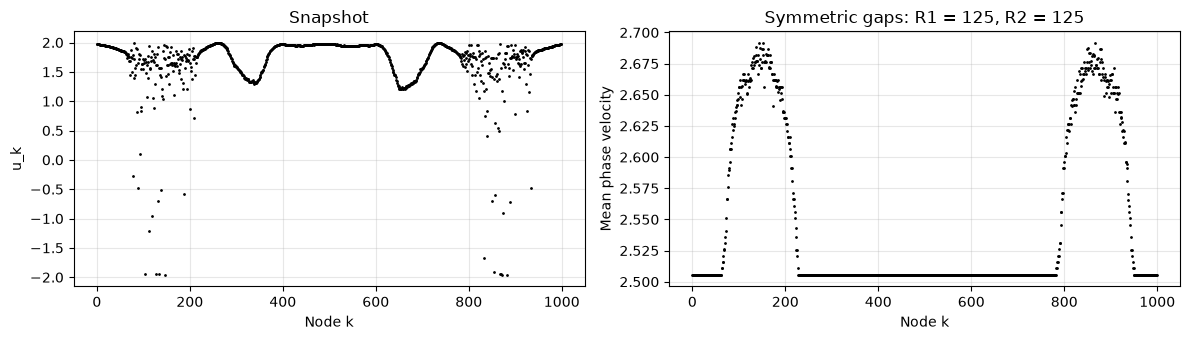

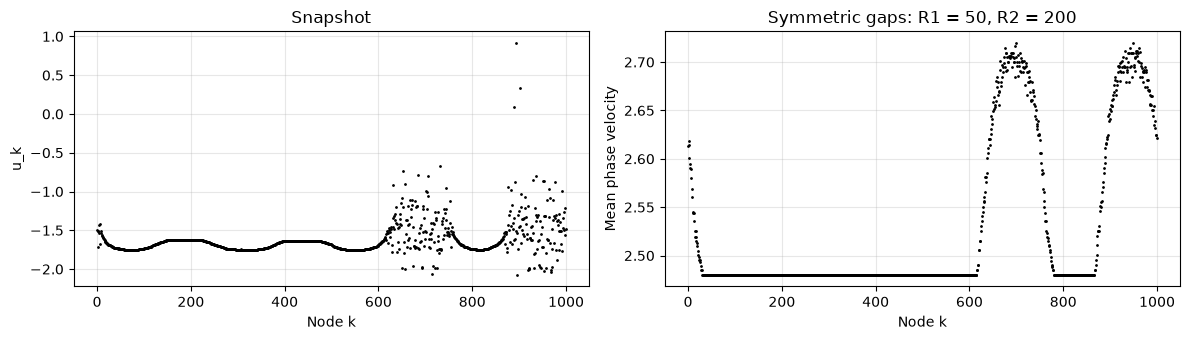

C:\Users\fadid\AppData\Local\Temp\ipykernel_26628\148051626.py:32: RuntimeWarning: overflow encountered in power
  du = (X[0] - X[0]**3 / 3 - X[1] + coupling_weight * coupling_u) / epsilon
e:\Research\simulationNew\Lib\site-packages\scipy\integrate\_ivp\rk.py:684: RuntimeWarning: invalid value encountered in dot
  err5 = np.dot(K.T, self.E5) / scale
e:\Research\simulationNew\Lib\site-packages\scipy\integrate\_ivp\rk.py:685: RuntimeWarning: invalid value encountered in dot
  err3 = np.dot(K.T, self.E3) / scale


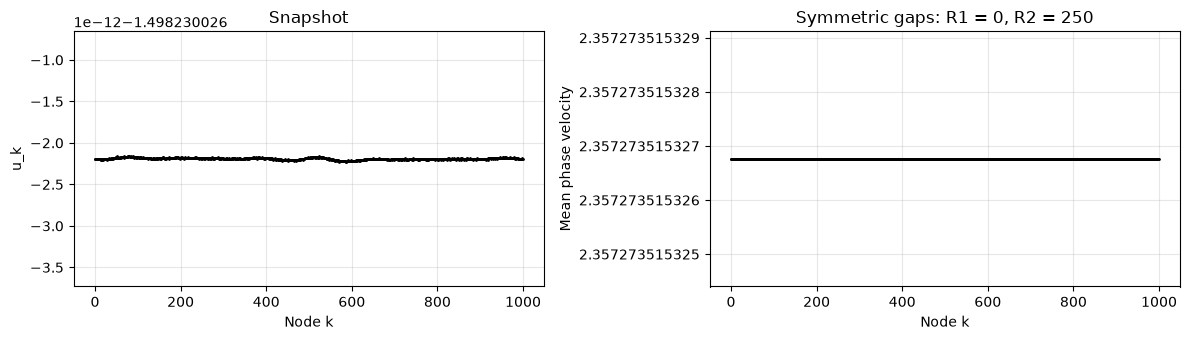

R1 = 250: {'omega_coh': 2.3626429934970337, 'delta_omega': 1.0711901474724783e-05, 'N_incoh': 0.0, 'M_incoh': 0.006446996577906372}
R1 = 200: {'omega_coh': 2.4428596944456524, 'delta_omega': 0.07530806883436414, 'N_incoh': 0.214, 'M_incoh': 14.915929283298823}
R1 = 125: {'omega_coh': 2.5056717449818238, 'delta_omega': 0.18593495872365784, 'N_incoh': 0.295, 'M_incoh': 42.343929027472974}
R1 = 50: {'omega_coh': 2.480260348977036, 'delta_omega': 0.2395139405054061, 'N_incoh': 0.276, 'M_incoh': 49.805280539140135}
R1 = 0: {'omega_coh': 2.3572735153267605, 'delta_omega': 1.7763568394002505e-15, 'N_incoh': 0.0, 'M_incoh': 3.1752378504279477e-13}


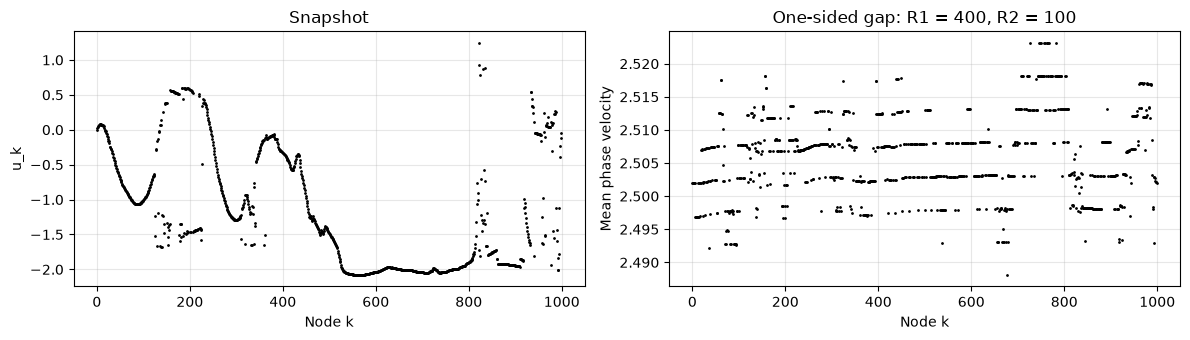

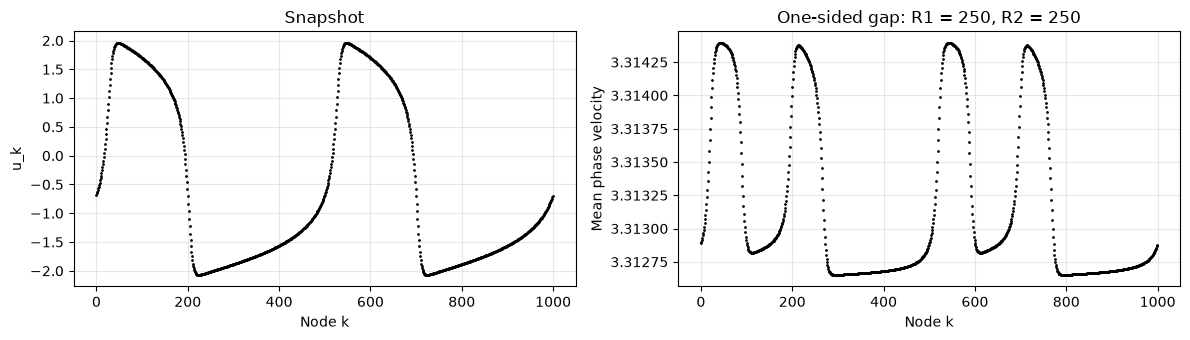

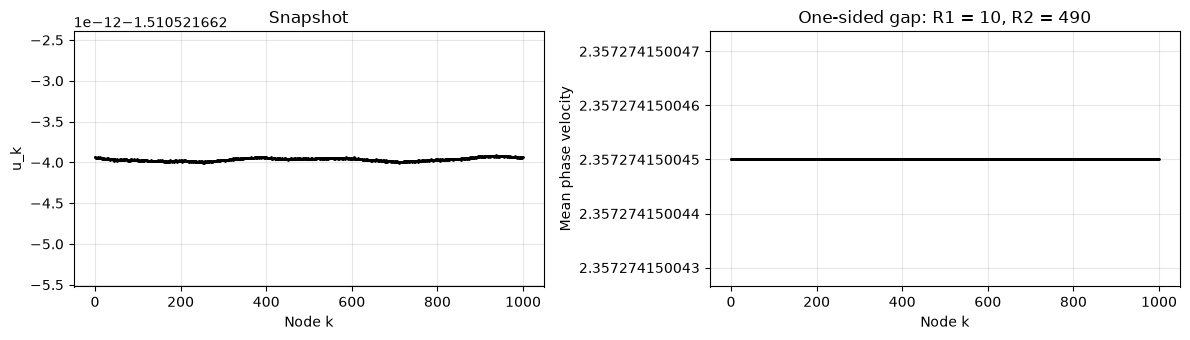

In [10]:
#two equal gaps, one on each side of every node
R_total = int(0.25 * N_run)
G = int(0.10 * N_run)
gap_results = []
for R1 in [R_total, int(0.8*R_total), R_total//2, int(0.2*R_total), 0]:
    C_gap = symmetric_gap_matrix(N_run, R1, R_total - R1, G)
    u, omega = simulate_fhn(C_gap, sigma=0.30, seed=42)
    plot_case(u, omega, f'Symmetric gaps: R1 = {R1}, R2 = {R_total - R1}')
    gap_results.append((R1, coherence_measures(omega)))

for R1, measures in gap_results:
    print(f'R1 = {R1}:', measures)

#one sided case: all the links go right and there is one gap
R_one_sided = int(0.50 * N_run)
for R1 in [int(0.8*R_one_sided), R_one_sided//2, max(1, int(0.02*R_one_sided))]:
    C_gap = one_sided_gap_matrix(N_run, R1, R_one_sided - R1, G)
    u, omega = simulate_fhn(C_gap, sigma=0.30, seed=42)
    plot_case(u, omega, f'One-sided gap: R1 = {R1}, R2 = {R_one_sided - R1}')

### Quantitative gap sweeps (Figs. 8 and 10)

The optional sweeps report the mean and standard deviation across independent initial conditions. They are disabled by default because each point requires multiple full integrations.


In [11]:
RUN_GAP_SWEEP = False
n_runs_sweep = 3

def sweep(builder, R_tot, R1_values, sigma=0.30):
    mean_values, std_values = [], []
    for R1 in R1_values:
        C = builder(N_run, R1, R_tot - R1, G)
        measurements = []
        for seed in range(n_runs_sweep):
            _, omega = simulate_fhn(C, sigma, seed=seed)
            m = coherence_measures(omega)
            measurements.append([m["omega_coh"], m["delta_omega"],
                                 m["N_incoh"], m["M_incoh"]])
        measurements = np.asarray(measurements)
        mean_values.append(measurements.mean(axis=0))
        std_values.append(measurements.std(axis=0))
    return np.asarray(mean_values), np.asarray(std_values)

def plot_sweep(R1_values, mean_values, std_values, title):
    names = ["<omega_coh>", "delta omega", "N_incoh", "M_incoh"]
    fig, axes = plt.subplots(2, 2, figsize=(9, 6), sharex=True)
    for ax, i, name in zip(axes.ravel(), range(4), names):
        ax.errorbar(R1_values, mean_values[:, i], std_values[:, i],
                    fmt="ro-", ms=3)
        ax.set(ylabel=name)
        ax.grid(alpha=0.3)
    for ax in axes[1]:
        ax.set_xlabel("R1")
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

if RUN_GAP_SWEEP:
    R1s = [sc(v) for v in [0, 50, 100, 125, 150, 200, 250]]
    mean_values, std_values = sweep(symmetric_gap_matrix, sc(250), R1s)
    plot_sweep(R1s, mean_values, std_values, "Symmetric gaps (Fig. 8)")

    R1s = [sc(v) for v in [0, 100, 200, 250, 300, 400, 500]]
    mean_values, std_values = sweep(one_sided_gap_matrix, sc(500), R1s)
    plot_sweep(R1s, mean_values, std_values, "One-sided gap (Fig. 10)")

## VI. Fractal/hierarchical gaps

Each pattern is divided by its own number of links because they do not all have the same amount. The last two patterns have the same fractal dimension but the links are arranged differently.

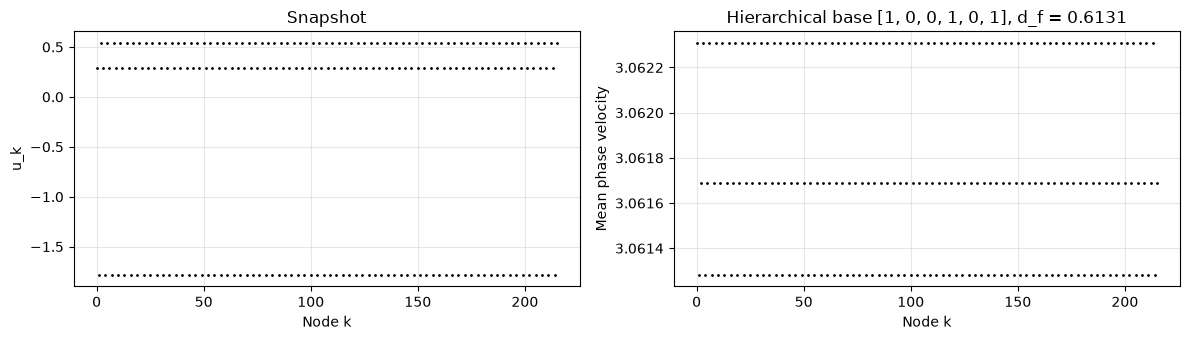

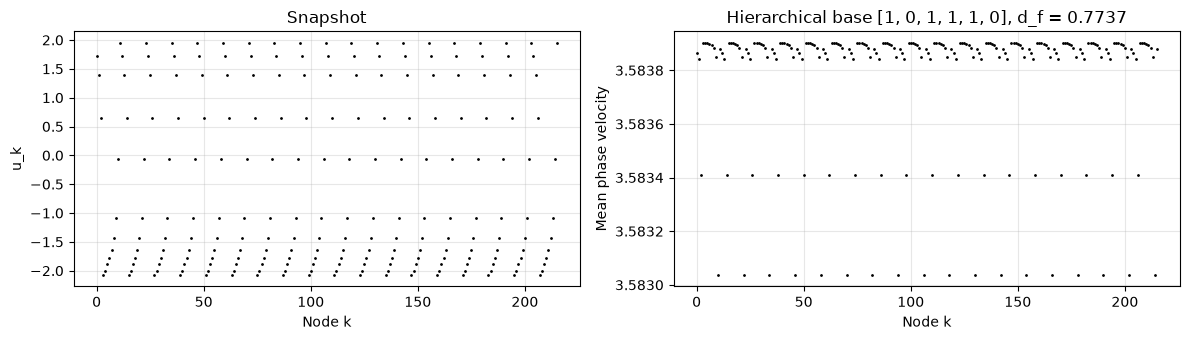

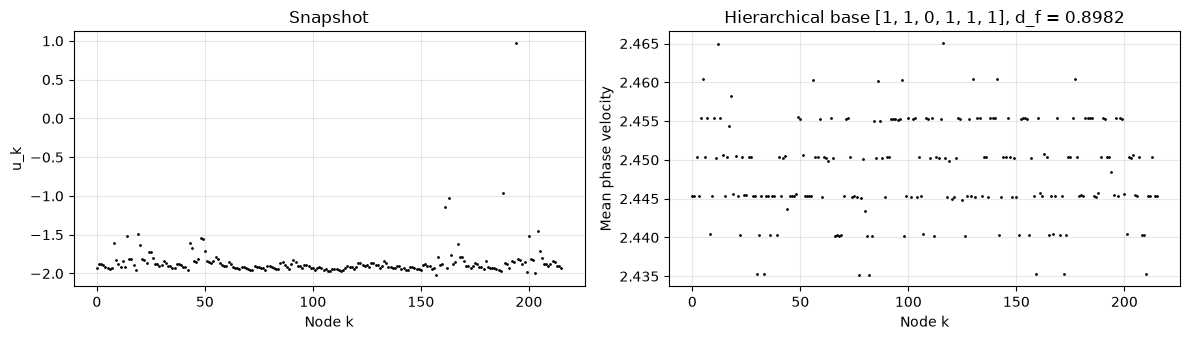

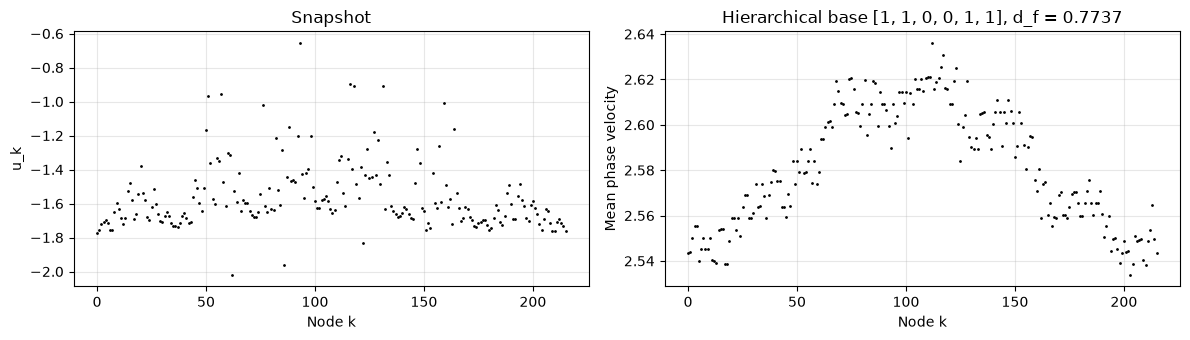

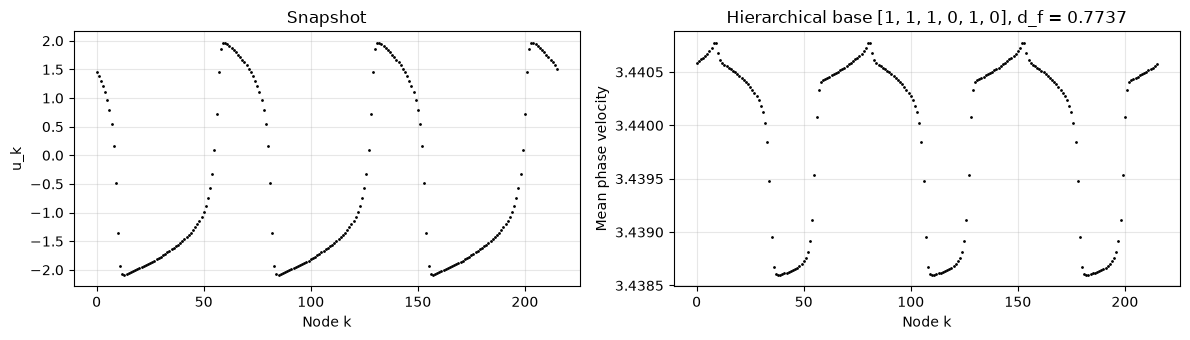

In [12]:
RUN_PAPER_SCALE = False
hierarchical_iterations = 4 if RUN_PAPER_SCALE else 3
N_hierarchical = 6 ** hierarchical_iterations
hierarchical_patterns = [[1, 0, 0, 1, 0, 1], [1, 0, 1, 1, 1, 0],
                         [1, 1, 0, 1, 1, 1], [1, 1, 0, 0, 1, 1],
                         [1, 1, 1, 0, 1, 0]]
#the faster version uses three repeats, but the same idea
for pattern in hierarchical_patterns:
    C = build_fractal_matrix(pattern, iterations=hierarchical_iterations)
    u, omega = simulate_fhn(C, sigma=0.30, seed=42)
    d_f = np.log(sum(pattern)) / np.log(len(pattern))
    plot_case(u, omega, f"Hierarchical base {pattern}, d_f = {d_f:.4f}")